In [98]:
import networkx as nx
import numpy as np

import matplotlib.pyplot as plt
%matplotlib inline

In [44]:
n = 5

In [45]:
G = nx.gnp_random_graph(n, 0.5, 42, directed=True)

In [120]:
weights = dict(
    zip(
        list(G.edges), 
        np.random.randint(1, 100, G.number_of_edges())
    )
)

In [121]:
nx.set_edge_attributes(G, weights, name='weight')

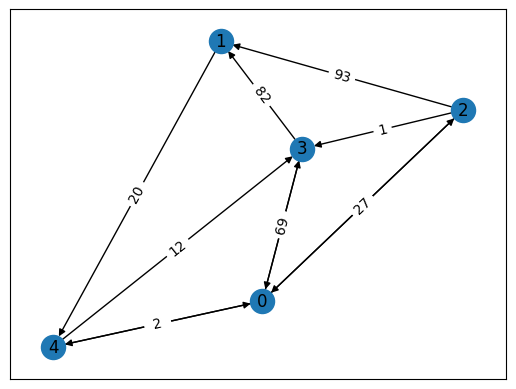

In [122]:
pos = nx.spring_layout(G, seed=42)
nx.draw_networkx(G, pos=pos)
nx.draw_networkx_edge_labels(G, pos=pos, edge_labels=weights)
plt.show()

In [259]:
# Независимая проверка (поиск хоть какого-нибудь гам. цикла для небольшого графа)
def hamiltonian_cycle(G):
    n = len(G)

    for cycle in nx.simple_cycles(G):
        if len(cycle) == n:
            return cycle + [cycle[0]]

    return None

In [124]:
hamiltonian_cycle(G)

[0, 2, 1, 4, 3, 0]

In [125]:
C = nx.adjacency_matrix(G).toarray()
C

array([[ 0,  0, 42, 14, 60],
       [ 0,  0,  0,  0, 20],
       [27, 93,  0,  1,  0],
       [69, 82,  0,  0,  0],
       [ 2,  0,  0, 12,  0]])

In [126]:
U = np.full((n, n), np.infty)
U

array([[inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf],
       [inf, inf, inf, inf, inf]])

In [127]:
M = 10000

In [128]:
np.fill_diagonal(C, -M)

In [129]:
C

array([[-10000,      0,     42,     14,     60],
       [     0, -10000,      0,      0,     20],
       [    27,     93, -10000,      1,      0],
       [    69,     82,      0, -10000,      0],
       [     2,      0,      0,     12, -10000]])

In [130]:
new_C = np.block([
    [U, C.transpose()],
    [C, U]
])
new_C

array([[     inf,      inf,      inf,      inf,      inf, -1.0e+04,
         0.0e+00,  2.7e+01,  6.9e+01,  2.0e+00],
       [     inf,      inf,      inf,      inf,      inf,  0.0e+00,
        -1.0e+04,  9.3e+01,  8.2e+01,  0.0e+00],
       [     inf,      inf,      inf,      inf,      inf,  4.2e+01,
         0.0e+00, -1.0e+04,  0.0e+00,  0.0e+00],
       [     inf,      inf,      inf,      inf,      inf,  1.4e+01,
         0.0e+00,  1.0e+00, -1.0e+04,  1.2e+01],
       [     inf,      inf,      inf,      inf,      inf,  6.0e+01,
         2.0e+01,  0.0e+00,  0.0e+00, -1.0e+04],
       [-1.0e+04,  0.0e+00,  4.2e+01,  1.4e+01,  6.0e+01,      inf,
             inf,      inf,      inf,      inf],
       [ 0.0e+00, -1.0e+04,  0.0e+00,  0.0e+00,  2.0e+01,      inf,
             inf,      inf,      inf,      inf],
       [ 2.7e+01,  9.3e+01, -1.0e+04,  1.0e+00,  0.0e+00,      inf,
             inf,      inf,      inf,      inf],
       [ 6.9e+01,  8.2e+01,  0.0e+00, -1.0e+04,  0.0e+00,      i

In [131]:
new_G = nx.from_numpy_array(new_C)

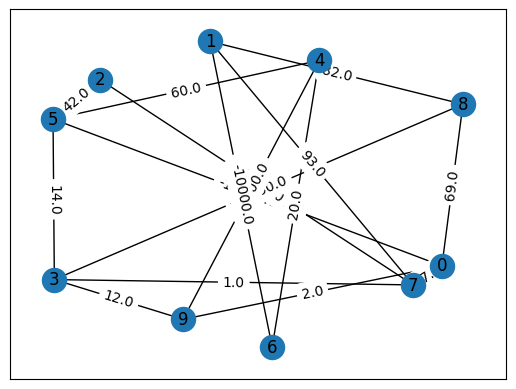

In [163]:
G2 = nx.Graph(
    (u, v, data)
    for u, v, data in new_G.edges(data=True)
    if np.isfinite(data['weight'])
)
pos1 = nx.spring_layout(G2, seed=123)
nx.draw_networkx(G2, pos=pos1)
nx.draw_networkx_edge_labels(G, pos=pos1, edge_labels=nx.get_edge_attributes(G2, 'weight'))
plt.show()

In [184]:
import pyomo.environ as pyo

In [179]:
from itertools import combinations

Из-за inf ломается оптимизация :(

In [225]:
U = np.full((n, n), 10**6)
C2 = np.block([
    [U, C.transpose()],
    [C, U]
])

In [246]:
model = pyo.ConcreteModel()
model.n = pyo.Param(initialize=G2.number_of_nodes(), within=pyo.NonNegativeIntegers)
model.I = pyo.RangeSet(0, model.n - 1)
model.x = pyo.Var(model.I, model.I, domain=pyo.Binary)

model.obj = pyo.Objective(
    expr=sum(C2[i, j] * model.x[i, j] for i, j in combinations(model.I, 2)),
    sense=pyo.minimize
)

# Степень вершины = 2
model.vertex_degree = pyo.ConstraintList()

for j in model.I:
    model.vertex_degree.add(sum(model.x[i, j] for i in model.I if i != j) == 2)

# Запрет циклов (SEC)
model.subtour = pyo.ConstraintList()

for lenS in range(3, int(pyo.value(model.n)) // 2 + 1):
    for S in combinations(model.I, lenS):
        model.subtour.add(sum(model.x[i, j] for i in S for j in S if i<j) <= len(S) - 1)

# Симметричность
model.symmetry = pyo.ConstraintList()
for i, j in combinations(model.I, 2):
    model.symmetry.add(model.x[i, j] == model.x[j, i])

# Обработка inf (запрещённых рёбер)
for i, j in combinations(model.I, 2):
    if C2[i, j] == 10**6:
        model.x[i, j].fix(0)
        model.x[j, i].fix(0)

In [247]:
solver = pyo.SolverFactory(
    "cbc",
    executable=r"C:\Users\User\Documents\Solvers\CBC\bin\cbc.exe"
)

print(solver.available())

True


In [248]:
result = solver.solve(model, tee=False)

In [249]:
result

{'Problem': [{'Name': 'unknown', 'Lower bound': -49998.0, 'Upper bound': -49998.0, 'Number of objectives': 1, 'Number of constraints': 310, 'Number of variables': 25, 'Number of binary variables': 50, 'Number of integer variables': 50, 'Number of nonzeros': 16, 'Sense': 'minimize'}], 'Solver': [{'Status': 'ok', 'User time': -1.0, 'System time': 0.16, 'Wallclock time': 0.16, 'Termination condition': 'optimal', 'Termination message': 'Model was solved to optimality (subject to tolerances), and an optimal solution is available.', 'Statistics': {'Branch and bound': {'Number of bounded subproblems': 0, 'Number of created subproblems': 0}, 'Black box': {'Number of iterations': 0}}, 'Error rc': 0, 'Time': 0.24864411354064941}], 'Solution': [OrderedDict([('number of solutions', 0), ('number of solutions displayed', 0)])]}

In [250]:
pyo.value(model.obj)

-49998.0

In [255]:
G2h_edges = [
    (i, j)
    for i, j in combinations(model.I, 2)
    if pyo.value(model.x[i, j]) > 0.5
]
print(G2h_edges)

[(0, 5), (0, 9), (1, 5), (1, 6), (2, 7), (2, 8), (3, 6), (3, 8), (4, 7), (4, 9)]


In [252]:
from collections import defaultdict

In [256]:
adj = defaultdict(list)

for i, j in G2h_edges:
    adj[i].append(j)
    adj[j].append(i)

start = 0
cycle = [start]
prev = None
curr = start

while True:
    nxt = next(v for v in adj[curr] if v != prev)

    if nxt == start:
        break

    cycle.append(nxt)
    prev, curr = curr, nxt

cycle.append(start)
print(cycle)

[0, 5, 1, 6, 3, 8, 2, 7, 4, 9, 0]


In [258]:
asymm_cycle = [v % n for v in cycle[::2]]
print(asymm_cycle)

[0, 1, 3, 2, 4, 0]
